In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf

import riskkit as rk
warnings.filterwarnings("ignore")

# ---------------- CONFIG: change these ----------------
TICKERS   = ["RELIANCE.NS", "HDFCBANK.NS", "INFY.NS", "TCS.NS", "ICICIBANK.NS"]
WEIGHTS   = [0.20, 0.20, 0.20, 0.20, 0.20]      
START     = "2014-01-01"
END       = None                                 
ALPHA     = 0.99                                 
PORTFOLIO = 10_000_000                           
WINDOW    = 750                                  
REFIT     = 20                                   
# -------------------------------------------------------
SIMULATED = os.environ.get("RISK_SIMULATED") == "1"   
os.makedirs("outputs", exist_ok=True); os.makedirs("data", exist_ok=True)


INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
mpl.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white"})
def style(ax, title=None, ylabel=None):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c9c8c3")
    ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    if title: ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold")
    if ylabel: ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
if SIMULATED: print("WARNING: using SIMULATED data. Do not quote these results.")

In [3]:
prices = rk.load_prices(TICKERS, START, END, cache_path="data/prices.csv", simulated=SIMULATED)
print(prices.shape, "| from", prices.index[0].date(), "to", prices.index[-1].date())
print("missing values:", int(prices.isna().sum().sum()))
prices.tail()

(3151, 5) | from 2014-01-01 to 2026-10-09
missing values: 0


Ticker,RELIANCE.NS,HDFCBANK.NS,INFY.NS,TCS.NS,ICICIBANK.NS
Date,,,,,
2026-10-05,1186.400024,704.799988,1020.500000,2114.399902,1332.000000
2026-10-06,1218.000000,711.450012,1013.849976,2100.000000,1342.800049
2026-10-07,1207.699951,702.750000,992.000000,2080.300049,1357.500000
2026-10-08,1178.000000,692.250000,997.000000,2076.000000,1349.000000
2026-10-09,1170.300049,707.250000,1023.400024,2156.000000,1355.000000


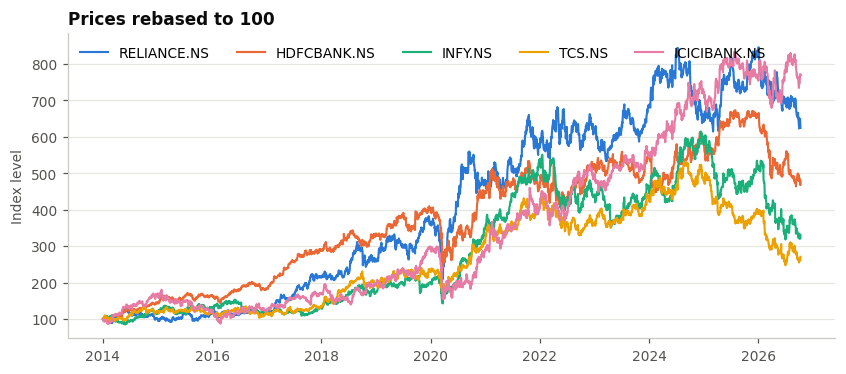

In [4]:
rebased = prices / prices.iloc[0] * 100         
fig, ax = plt.subplots(figsize=(9, 3.6))
for c, col in zip(rebased.columns, SERIES):
    ax.plot(rebased.index, rebased[c], color=col, lw=1.4, label=c)
style(ax, "Prices rebased to 100", "Index level")
ax.legend(frameon=False, fontsize=9, ncol=len(rebased.columns), loc="upper left")
fig.savefig("outputs/01_prices.png", dpi=150, bbox_inches="tight"); plt.show()

In [5]:
r = rk.portfolio_returns(prices, WEIGHTS)
stats_tbl = rk.return_stats(r)
stats_tbl.to_frame("value").round(4)

,value
observations,3150.0000
mean_daily_%,0.0618
std_daily_%,1.0977
annualised_vol_%,17.4255
skew,-0.4512
excess_kurtosis,12.2465
worst_day_%,-12.1510
best_day_%,10.4448
jarque_bera_p,0.0000


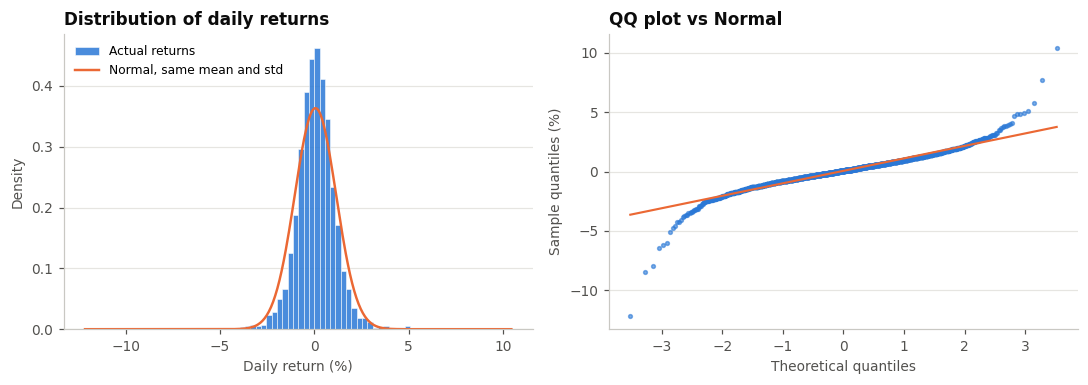

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.hist(r * 100, bins=80, density=True, color=SERIES[0], alpha=0.85, edgecolor="white", linewidth=0.4, label="Actual returns")
x = np.linspace(r.min() * 100, r.max() * 100, 400)
ax.plot(x, stats.norm.pdf(x, r.mean() * 100, r.std() * 100), color=SERIES[1], lw=1.6, label="Normal, same mean and std")
style(ax, "Distribution of daily returns", "Density"); ax.set_xlabel("Daily return (%)", color=MUTED, fontsize=9)
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
(osm, osr), (slope, icpt, _) = stats.probplot(r, dist="norm")
ax.scatter(osm, osr * 100, s=6, color=SERIES[0], alpha=0.6)
ax.plot(osm, (slope * osm + icpt) * 100, color=SERIES[1], lw=1.4)
style(ax, "QQ plot vs Normal", "Sample quantiles (%)"); ax.set_xlabel("Theoretical quantiles", color=MUTED, fontsize=9)
fig.tight_layout(); fig.savefig("outputs/02_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

In [7]:

adf_price = adfuller(prices.iloc[:, 0])[1]
adf_ret = adfuller(r)[1]
print(f"ADF p-value, first stock's price : {adf_price:.4f}   (> 0.05 => non-stationary)")
print(f"ADF p-value, portfolio returns   : {adf_ret:.6f}   (< 0.05 => stationary)")

ADF p-value, first stock's price : 0.7183   (> 0.05 => non-stationary)
ADF p-value, portfolio returns   : 0.000000   (< 0.05 => stationary)


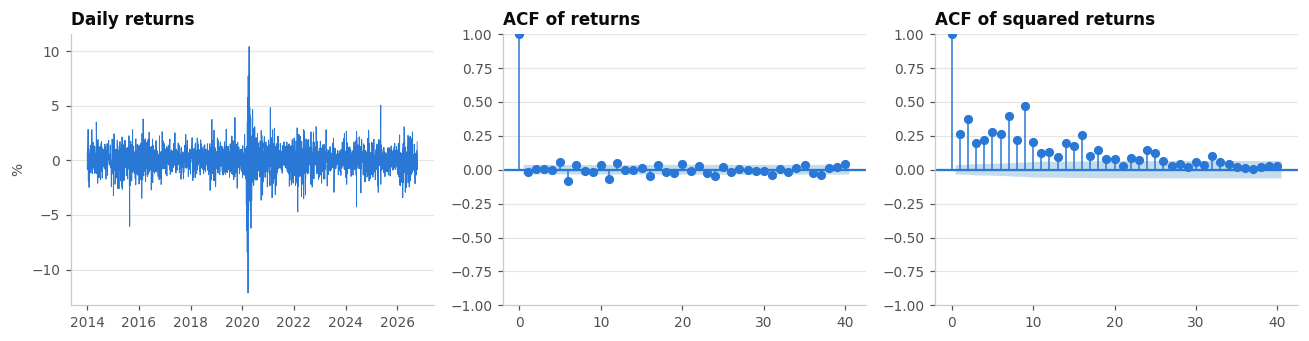

ARCH-LM test p-value: 0.000000  (< 0.05 => volatility clustering is real, so GARCH is justified)


In [8]:
# Volatility clustering: returns look unpredictable, but SQUARED returns are autocorrelated.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].plot(r.index, r * 100, color=SERIES[0], lw=0.6); style(axes[0], "Daily returns", "%")
for ax, series, t in [(axes[1], r, "ACF of returns"), (axes[2], r ** 2, "ACF of squared returns")]:
    plot_acf(series, lags=40, ax=ax, title="", color=SERIES[0], vlines_kwargs={"colors": SERIES[0], "linewidth": 1})
    style(ax, t)
fig.tight_layout(); fig.savefig("outputs/03_clustering.png", dpi=150, bbox_inches="tight"); plt.show()
lm_stat, lm_p, _, _ = het_arch(r - r.mean(), nlags=10)
print(f"ARCH-LM test p-value: {lm_p:.6f}  (< 0.05 => volatility clustering is real, so GARCH is justified)")

## 3. Volatility models

**Rolling standard deviation** (baseline): the std of the last 30 days. Simple, but it reacts slowly and forgets everything older than 30 days.

**GARCH(1,1)** with Student-t errors: tomorrow's variance depends on today's shock and today's variance.

$$\sigma_{t+1}^2 = \omega + \alpha\,\varepsilon_t^2 + \beta\,\sigma_t^2$$

- `alpha`: how strongly a new shock moves volatility
- `beta`: how long volatility stays elevated
- `alpha + beta` close to 1 means shocks fade slowly
- Student-t errors give fat tails; `nu` is the degrees of freedom (lower = fatter tails)

In [9]:
res = rk.fit_garch(r)
p = res.params
persistence = p["alpha[1]"] + p["beta[1]"]
half_life = np.log(0.5) / np.log(persistence)
print(res.params.round(4).to_string())
print(f"\npersistence (alpha+beta) = {persistence:.3f}  |  shock half-life = {half_life:.1f} days  |  t degrees of freedom = {p['nu']:.1f}")

mu          0.0716
omega       0.0256
alpha[1]    0.0490
beta[1]     0.9252
nu          7.2245

persistence (alpha+beta) = 0.974  |  shock half-life = 26.5 days  |  t degrees of freedom = 7.2


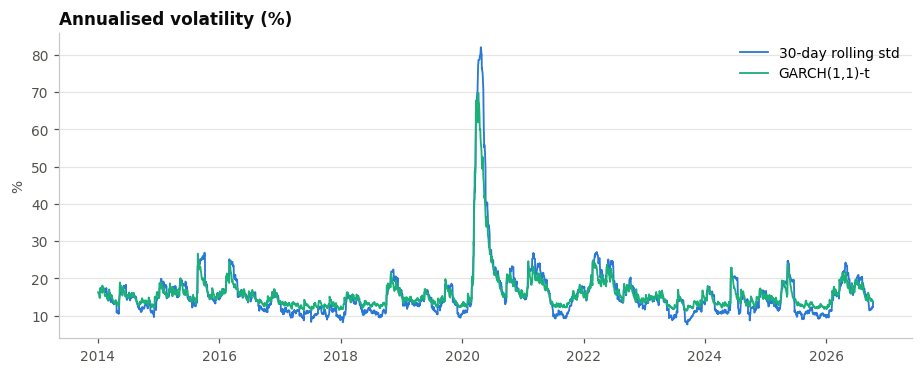

In [10]:
garch_vol = pd.Series(np.asarray(res.conditional_volatility), index=r.index) * np.sqrt(252)   # annualised, % (returns were scaled x100)
roll_vol = r.rolling(30).std() * np.sqrt(252) * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(roll_vol.index, roll_vol, color=SERIES[0], lw=1.2, label="30-day rolling std")
ax.plot(r.index, garch_vol, color=SERIES[2], lw=1.2, label="GARCH(1,1)-t")
style(ax, "Annualised volatility (%)", "%"); ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.savefig("outputs/04_volatility.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Value at Risk and Expected Shortfall

- **VaR (99%, 1 day):** a loss we expect to be exceeded on only 1 day in 100.
- **Expected Shortfall:** the average loss on those bad days. It says how bad it gets once VaR is breached, which VaR does not.

| Method | Idea | Weakness |
|---|---|---|
| Historical | Take the 1st percentile of past returns | Slow to react, and has no information about the future volatility level |
| Parametric (Normal) | Mean and std plus the Normal quantile | Normal underestimates tail risk |
| GARCH-t | Forecast tomorrow's volatility, then apply a fat-tailed quantile | More moving parts, parameters can be unstable |

In [11]:
tbl = rk.var_table(r, ALPHA, PORTFOLIO)
tbl[["VaR_%", "ES_%", "VaR_money", "ES_money"]].round(2)

,VaR_%,ES_%,VaR_money,ES_money
Historical,2.68,4.36,268241.01,435929.14
Parametric (Normal),2.49,2.86,249179.99,286377.44
GARCH-t,2.26,2.85,226174.23,285202.28


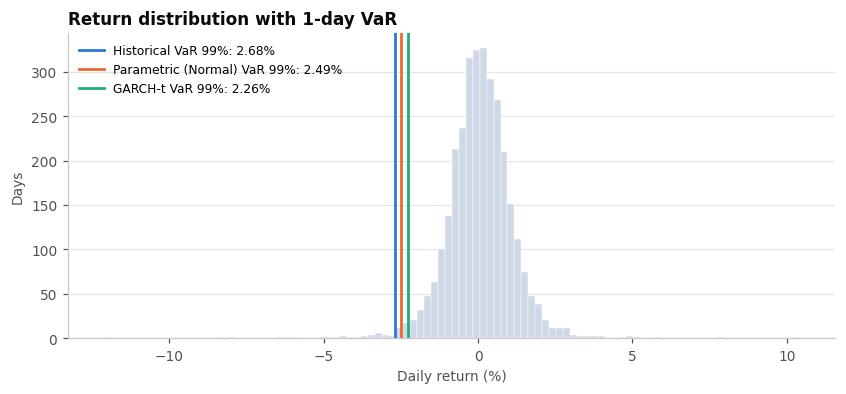

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(r * 100, bins=100, color="#cfd8e6", edgecolor="white", linewidth=0.3)
for m, col in rk.COLORS.items():
    ax.axvline(-tbl.loc[m, "VaR_%"], color=col, lw=1.8, label=f"{m} VaR {ALPHA:.0%}: {tbl.loc[m, 'VaR_%']:.2f}%")
style(ax, "Return distribution with 1-day VaR", "Days"); ax.set_xlabel("Daily return (%)", color=MUTED, fontsize=9)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig("outputs/05_var_lines.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:

h = 10
(tbl[["VaR_money"]] * np.sqrt(h)).rename(columns={"VaR_money": f"{h}-day VaR (INR, sqrt-time)"}).round(0)

,"10-day VaR (INR, sqrt-time)"
Historical,848253.0
Parametric (Normal),787976.0
GARCH-t,715226.0


## 5. Backtesting

For every day from the 751st onward, we ask: *what VaR would this method have given the evening before, using only data available then?* Then we check whether the actual loss exceeded it. That is a **breach**.

At 99% confidence we expect about **1% breaches**. Too many means the model understates risk. Far too few means it is too conservative and ties up capital.

Three tests:
- **Kupiec (proportion of failures):** is the breach *rate* consistent with 1%?
- **Christoffersen (independence):** do breaches *cluster*? Clustering means the model reacts too slowly.
- **Basel traffic light:** green (0-4 breaches per 250 days), yellow (5-9), red (10+).

A method passes only if both p-values are above 0.05. This cell refits GARCH many times and takes a minute or two.

In [14]:
bt = rk.rolling_backtest(r, ALPHA, WINDOW, REFIT)
print(bt.shape, "| backtest period:", bt.index[0].date(), "to", bt.index[-1].date())
summary = rk.backtest_summary(bt, ALPHA)
summary.round(4)

(2400, 5) | backtest period: 2017-01-23 to 2026-10-09


,days,breaches,expected,breach_rate_%,per_250_days,basel_zone,kupiec_p,independence_p,verdict
method,,,,,,,,,
Historical,2400,28,24.0,1.1667,2.9167,green,0.4240,0.0002,FAIL
Parametric (Normal),2400,38,24.0,1.5833,3.9583,green,0.0081,0.0002,FAIL
GARCH-t,2400,37,24.0,1.5417,3.8542,green,0.0135,0.0198,FAIL


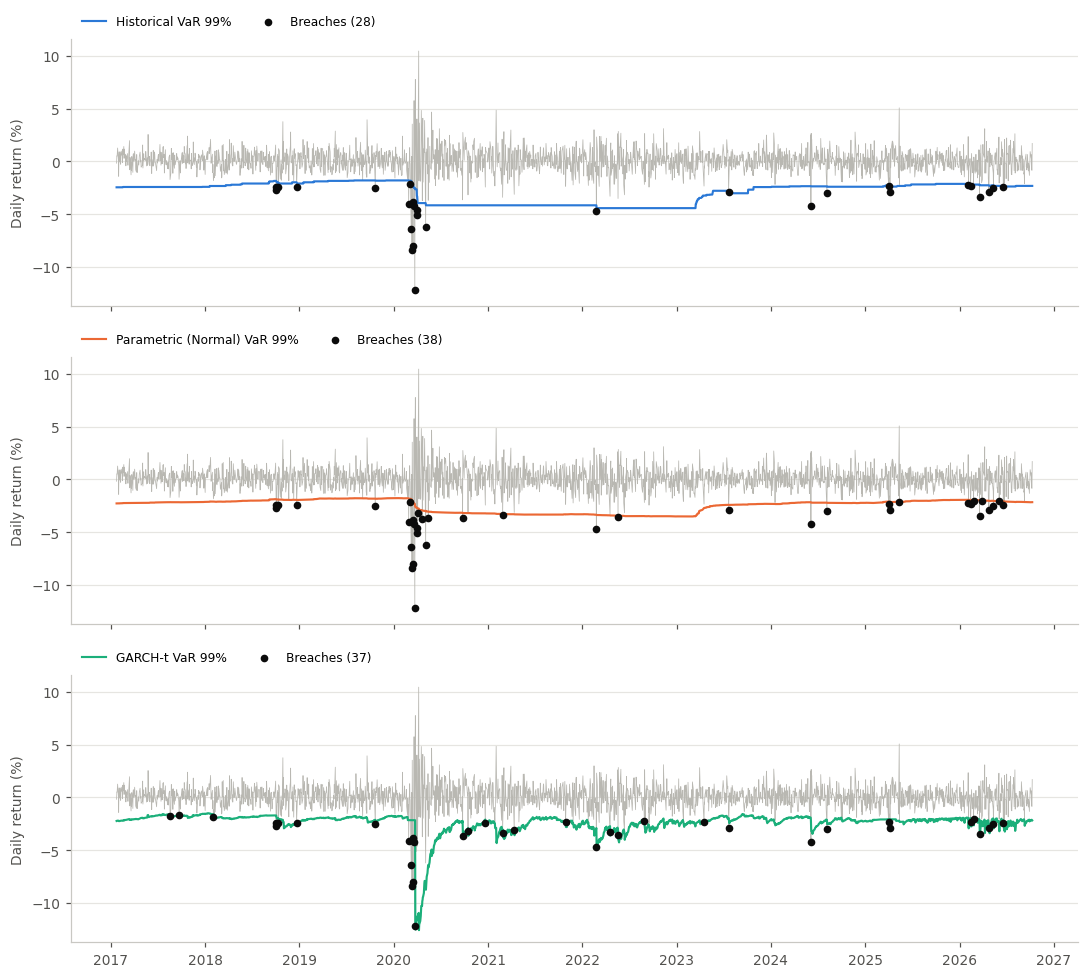

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, sharey=True)
for ax, m in zip(axes, ["Historical", "Parametric (Normal)", "GARCH-t"]):
    col = rk.COLORS[m]
    ax.plot(bt.index, bt["return"] * 100, color="#b9b8b2", lw=0.5)
    ax.plot(bt.index, -bt[m] * 100, color=col, lw=1.4, label=f"{m} VaR {ALPHA:.0%}")
    b = bt[bt["return"] < -bt[m]]
    ax.scatter(b.index, b["return"] * 100, s=16, color=INK, zorder=3, label=f"Breaches ({len(b)})")
    style(ax, None, "Daily return (%)"); ax.legend(frameon=False, fontsize=8, loc="lower left", ncol=2, bbox_to_anchor=(0, 1.0))
fig.tight_layout(); fig.savefig("outputs/06_backtest.png", dpi=150, bbox_inches="tight"); plt.show()

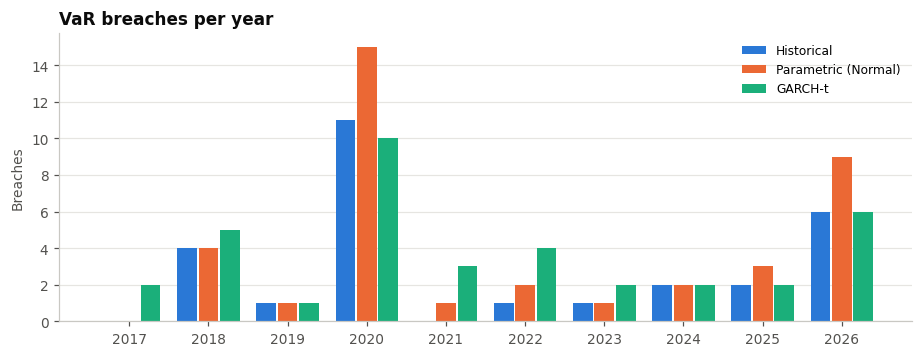

In [16]:
# When did the breaches happen? Clusters in crisis years are the classic sign of a model that reacts too slowly.
by_year = pd.DataFrame({m: (bt["return"] < -bt[m]).groupby(bt.index.year).sum() for m in rk.COLORS})
fig, ax = plt.subplots(figsize=(10, 3.4))
bw = 0.27; xs = np.arange(len(by_year))
for i, (m, col) in enumerate(rk.COLORS.items()):
    ax.bar(xs + (i - 1) * bw, by_year[m], width=bw * 0.92, color=col, label=m)
ax.set_xticks(xs); ax.set_xticklabels(by_year.index)
style(ax, "VaR breaches per year", "Breaches"); ax.legend(frameon=False, fontsize=8)
fig.savefig("outputs/07_breaches_by_year.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Conclusions (fill these in from YOUR numbers)

Read your `summary` table and your charts, then complete:

1. **Distribution:** excess kurtosis was `___` and Jarque-Bera p was `___`, so returns are / are not Normal.
2. **Volatility:** `alpha + beta = ___`, a shock half-life of `___` days, and `nu = ___`.
3. **VaR levels:** at 99%, the Normal method gave `___%`, Historical `___%`, GARCH-t `___%`. The Normal method understated risk by `___%` relative to GARCH-t / did not.
4. **Backtest:** over `___` days, we expected `___` breaches. Historical had `___`, Normal had `___`, GARCH-t had `___`.
5. **Tests:** which methods passed Kupiec and independence? Which breaches clustered, and in which year (see the by-year chart)?
6. **Limits:** one window length (750 days), one confidence level, one portfolio, daily rebalancing assumed, no transaction costs. GARCH parameters can be unstable in short samples.

**Resume bullet template** (use only numbers you actually got):
> Built a market risk engine for an Indian equity portfolio: forecast volatility with GARCH(1,1)-t and computed 99% VaR / Expected Shortfall; backtested against Historical and Normal VaR over `___` trading days (Kupiec and Christoffersen tests), where GARCH-t recorded `___` breaches vs `___` expected.

In [17]:
summary.to_csv("outputs/backtest_summary.csv"); tbl.to_csv("outputs/var_table.csv"); bt.to_csv("outputs/backtest_daily.csv")
print("Saved results and charts to ./outputs")

Saved results and charts to ./outputs


In [18]:
###Conclusions

#Based on data from 1 Jan 2014 to 9 Oct 2026, equal-weighted portfolio of Reliance, HDFC Bank, Infosys, TCS and ICICI Bank. Daily numbers will change as new data comes in.

#Returns are not Normal. Excess kurtosis is 12.25 and the Jarque-Bera p-value is 0.0000. The worst day was -12.15% and the best was +10.44%. Extreme days happen far more often than a Normal distribution says.
#Volatility clusters. The ARCH-LM test p-value is 0.0000, so calm and turbulent periods come in streaks. In the GARCH model, alpha + beta = 0.974, so shocks fade slowly (half-life about 26.5 days). The t-distribution parameter is 7.2, which confirms fat tails.
#VaR and ES (99%, 1 day). Historical VaR is 2.68%, Normal is 2.49% and GARCH-t is 2.26%. The Expected Shortfall gap is larger: Historical is 4.36%, but Normal is only 2.86%. The Normal method understates the average loss on the worst days by roughly a third. GARCH-t is lowest because volatility is fairly calm right now. This will rise after a volatile period.
#Backtest. Over 2,400 trading days we expected about 24 breaches. Historical had 28, Normal had 38 and GARCH-t had 37.
#Tests. None of the three methods passed both tests.
#Historical has a breach rate close to 1% (Kupiec p = 0.42), but its breaches cluster (independence p = 0.0002).
#Normal and GARCH-t both have too many breaches (Kupiec p = 0.008 and 0.014).
#All three fall in the Basel green zone, so none would be penalised under the Basel traffic-light rules.
#What I take from this. GARCH-t did not beat the simpler methods on breach count. It does adapt to changing volatility, but it still produced too many breaches, and they clustered (independence p = 0.02). The most reliable result is that the Normal method underestimates tail losses.
#Limitations. One portfolio, one window length (750 days), one confidence level, daily rebalancing, no transaction costs, and Yahoo Finance data. Next steps could be a skewed-t distribution, a longer refit window or a 97.5% confidence level